# Introduction

In part 1 of this assessment, you will complete several requested SQL queries in order to extract data, analyze, and provide insights from a single provided SQL database. You will also visualize the key results of 3 of these queries. There are also several 'Reflection' questions that ask you to write out a text based answer in the provided markdown cell. Following the guided question and answer section, in part 2 you will explore a second dataset on your own using SQL in order to conduct a preliminary analysis. You will be asked to produce a very short slide presentation highlighting the work you did for this second section.

## Objectives
You will be able to:
- Interpret "word problems" and translate them into SQL queries
- Decide and perform whichever type of JOIN is best for retrieving desired data
- Use GROUP BY statements to apply aggregate functions like COUNT, MAX, MIN, and SUM
- Use the HAVING clause to compare different aggregates
- Write subqueries to decompose complex queries
- Visualize data using matplotlib, seaborn, or pandas
- Choose the correct chart type based on the given data


## Part 1: Guided SQL Queries

### Your Task: Querying a Customer Database

![toy car picture](images/toycars.jpg)


### Business Understanding
Your employer sells wholesale miniature models of products such as classic cars, motorcycles, and planes. They want you to pull several reports on different segments of their past customers, in order to better understand past sales as well as determine which customers will receive promotional material. They are also interested in investigating which products have performed the best, as well as having several smaller asks.

In addition to providing the requested data from the SQL database you have also been asked to create some basic visuals to display some of the more insightful information. It is up to your discretion to choose the correct plot/chart type for the data in question. **Questions that want you to visualize the results will be explicitly marked**.

### Data Understanding
You may remember this database from a previous lab. As a refresher, here's the ERD diagram for this database:

![ERD picture](images/ERD.png)

The queries you are asked to write will become more complex over the course of the lab.



### Getting Started
For this assessment you are expected to make use of both sqlite3 and the Pandas libraries in order to write, execute, and return SQL queries as a Pandas DataFrame. Assign each returned answer as its own explicit variable.

For the visualization piece you are expected to utilize either Pandas, Seaborn, or Matplotlib to create your visuals. Make sure you are providing verbose labels and titles according to the data you are being asked to visualize. Do not worry too much about choosing a 'style' or 'context' instead focus on conveying the requested information correctly.

### Step 1: Connect to Data

In the cell below
- Import the necessary libraries
- Establish a connection to the database data.sqlite

In [1]:
# Imports
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Create connection to database
conn = sqlite3.connect('data.sqlite')

### Step 2: Limited Edition California Product
The California sales rep team is interested in running promotional material for a new limited edition model they are releasing based on the famous San Francisco Cable Cars. This product will only be available to customer stores based in California and given its high price value they want to first target promotional material to existing California customers with a high credit limit. Upon communicating with the accounting department, a credit limit of over 25,000 is considered to be high. 

Execute a SQl query that returns which customers the sales rep team wants to market to first.
*Hint*: Make sure creditLimit is numeric.

In [2]:
# California customers with a high credit limit (over 25,000)
# creditLimit is stored as text, so it is CAST to a number before comparing
california_high_credit = pd.read_sql("""
SELECT customerNumber,
       customerName,
       contactFirstName,
       contactLastName,
       phone,
       city,
       state,
       CAST(creditLimit AS REAL) AS creditLimit
FROM customers
WHERE state = 'CA'
  AND CAST(creditLimit AS REAL) > 25000
ORDER BY creditLimit DESC;
""", conn)

california_high_credit

,customerNumber,customerName,contactFirstName,contactLastName,phone,city,state,creditLimit
0,124,Mini Gifts Distributors Ltd.,Susan,Nelson,4155551450,San Rafael,CA,210500.0
1,239,Collectable Mini Designs Co.,Valarie,Thompson,7605558146,San Diego,CA,105000.0
2,321,Corporate Gift Ideas Co.,Julie,Brown,6505551386,San Francisco,CA,105000.0
3,205,Toys4GrownUps.com,Julie,Young,6265557265,Pasadena,CA,90700.0
4,161,Technics Stores Inc.,Juri,Hashimoto,6505556809,Burlingame,CA,84600.0
5,450,The Sharp Gifts Warehouse,Sue,Frick,4085553659,San Jose,CA,77600.0
6,129,Mini Wheels Co.,Julie,Murphy,6505555787,San Francisco,CA,64600.0
7,487,Signal Collectibles Ltd.,Sue,Taylor,4155554312,Brisbane,CA,60300.0
8,347,"Men 'R' US Retailers, Ltd.",Brian,Chandler,2155554369,Los Angeles,CA,57700.0
9,475,West Coast Collectables Co.,Steve,Thompson,3105553722,Burbank,CA,55400.0


### Step 3: International Collectable Campaign

The international sales rep team has reached out to you to help them identify partners for a 'Collectable' marketing campaign that highlights the potential collectors value in purchasing these model kits. They want to try and promote a 'collect them all' mentality. The team had a great idea to partner with any of their international customers (non-US) who have "Collect" in their name as a tie in to the larger theme.

Execute a SQL that returns the customers in question.

In [3]:
# International (non-US) customers with "Collect" anywhere in their name
international_collect = pd.read_sql("""
SELECT customerNumber,
       customerName,
       contactFirstName,
       contactLastName,
       city,
       country
FROM customers
WHERE country != 'USA'
  AND customerName LIKE '%Collect%'
ORDER BY country;
""", conn)

international_collect

,customerNumber,customerName,contactFirstName,contactLastName,city,country
0,114,"Australian Collectors, Co.",Peter,Ferguson,Melbourne,Australia
1,471,"Australian Collectables, Ltd",Sean,Clenahan,Glen Waverly,Australia
2,382,Salzburg Collectables,Georg,Pipps,Salzburg,Austria
3,260,"Royal Canadian Collectables, Ltd.",Elizabeth,Lincoln,Tsawassen,Canada
4,227,Heintze Collectables,Palle,Ibsen,Århus,Denmark
5,353,Reims Collectables,Paul,Henriot,Reims,France
6,409,Stuttgart Collectable Exchange,Rita,Müller,Stuttgart,Germany
7,415,"Bavarian Collectables Imports, Co.",Michael,Donnermeyer,Munich,Germany
8,211,"King Kong Collectables, Co.",Mike,Gao,Central Hong Kong,Hong Kong
9,189,"Clover Collections, Co.",Dean,Cassidy,Dublin,Ireland


## Reflection Question:

Describe the WHERE clause you used in the above query to a non-technical manager who wants to be ensured that you are properly filtering and only selecting the requested data. How is the operator and conditional expression you are using acting to accomplish this?

## Type your answer in markdown here!

The WHERE clause works like a set of two checkpoints that every customer record must pass before it appears in the results.

1. **`country != 'USA'`**: the `!=` operator means "is not equal to". This checkpoint removes every customer based in the United States, so only international customers remain.
2. **`customerName LIKE '%Collect%'`**: the `LIKE` operator searches for a pattern inside the customer's name. The `%` symbols mean "any text can come before or after", so the name only needs to *contain* the word "Collect" somewhere. This catches variations such as "Collectables", "Collectors" and "Collections", without needing an exact name.

The two checkpoints are joined with **`AND`**, which means a customer must pass **both** to be selected. A US customer with "Collect" in its name is excluded, and an international customer without "Collect" in its name is also excluded. The result is exactly the requested group: international partners whose name ties in with the "collect them all" campaign.

### Step 4: USA Credit and Inventory Policy - Visual Required
The USA based product team is planning to adjust its credit policies and inventory allocation strategy based on the average credit limit of its customers. They would like to target this strategy at a state level with several goals in mind. 
1. Optimize inventory distribution:
    - States with higher average credit limits might be able to place larger orders, justifying priority in inventory allocation.
    - This could help ensure that states with more purchasing power always have products in stock.
2. Tailor credit policies:
    - Adjust credit limits for new customers based on the state average.
    - Identify states where they might be too conservative or too liberal with credit limits.
3. Target marketing and sales efforts:
    - Focus promotional campaigns on states with higher credit limits, potentially leading to larger orders.
    - Develop strategies to increase sales in states with lower average credit limits.

Execute a SQl query that returns the information required to address this ask.

In [4]:
# Average credit limit per US state
# creditLimit is CAST to a number so the average is calculated correctly
usa_state_credit = pd.read_sql("""
SELECT state,
       COUNT(customerNumber) AS num_customers,
       ROUND(AVG(CAST(creditLimit AS REAL)), 2) AS avg_credit_limit
FROM customers
WHERE country = 'USA'
GROUP BY state
ORDER BY avg_credit_limit DESC;
""", conn)

usa_state_credit

,state,num_customers,avg_credit_limit
0,NH,1,114200.00
1,NY,6,89966.67
2,PA,3,84766.67
3,CA,11,83854.55
4,NV,1,71800.00
5,MA,9,70755.56
6,CT,4,57350.00
7,NJ,1,43000.00


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

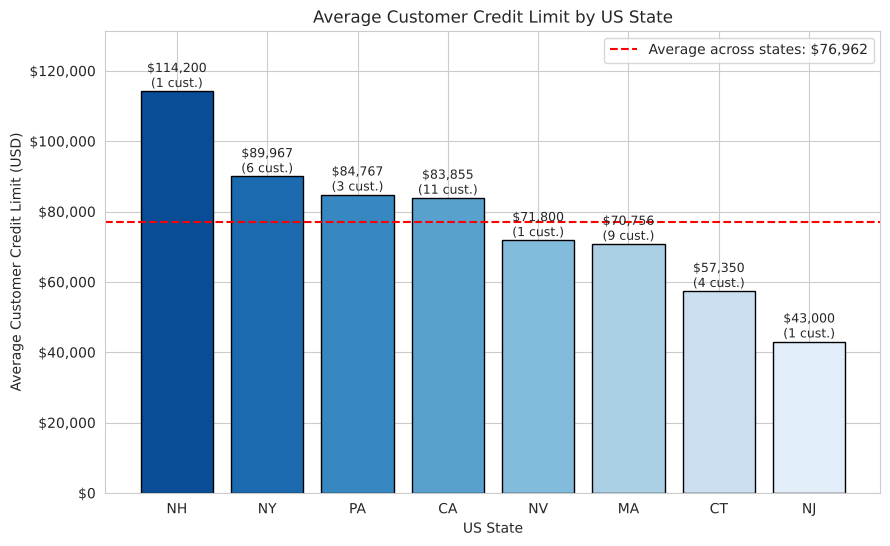

In [5]:
# Produce a visual to represent the average credit limit by state
sns.set_style('whitegrid')
fig, ax = plt.subplots(figsize=(10, 6))

colors = sns.color_palette('Blues_r', len(usa_state_credit))
bars = ax.bar(usa_state_credit['state'], usa_state_credit['avg_credit_limit'], color=colors, edgecolor='black')

# Dashed line showing the overall average across all states
overall_avg = usa_state_credit['avg_credit_limit'].mean()
ax.axhline(overall_avg, color='red', linestyle='--', label=f'Average across states: ${overall_avg:,.0f}')

# Annotate each bar with its value and number of customers
for bar, value, n in zip(bars, usa_state_credit['avg_credit_limit'], usa_state_credit['num_customers']):
    ax.annotate(f'${value:,.0f}\n({n} cust.)', (bar.get_x() + bar.get_width() / 2, value),
                ha='center', va='bottom', fontsize=9)

ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.set_ylim(0, usa_state_credit['avg_credit_limit'].max() * 1.15)
ax.set_xlabel('US State')
ax.set_ylabel('Average Customer Credit Limit (USD)')
ax.set_title('Average Customer Credit Limit by US State')
ax.legend()
plt.show()

### Step 5: Top Customers - Visual Required
The company is approaching its 10 year anniversary and wants to acknowledge and thank its top customers with personalized communication. They have asked you to determine the top 10 customers based on the total amount of payments made, making sure to return the customer name for clarity. 

Execute a SQl query that returns the information required to address this ask.


In [6]:
# Top 10 customers by total amount of payments made
top_10_customers = pd.read_sql("""
SELECT c.customerNumber,
       c.customerName,
       ROUND(SUM(CAST(p.amount AS REAL)), 2) AS total_payments
FROM customers AS c
JOIN payments AS p
    ON c.customerNumber = p.customerNumber
GROUP BY c.customerNumber, c.customerName
ORDER BY total_payments DESC
LIMIT 10;
""", conn)

top_10_customers

,customerNumber,customerName,total_payments
0,141,Euro+ Shopping Channel,715738.98
1,124,Mini Gifts Distributors Ltd.,584188.24
2,114,"Australian Collectors, Co.",180585.07
3,151,Muscle Machine Inc,177913.95
4,148,"Dragon Souveniers, Ltd.",156251.03
5,323,"Down Under Souveniers, Inc",154622.08
6,187,"AV Stores, Co.",148410.09
7,276,"Anna's Decorations, Ltd",137034.22
8,321,Corporate Gift Ideas Co.,132340.78
9,146,"Saveley & Henriot, Co.",130305.35


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

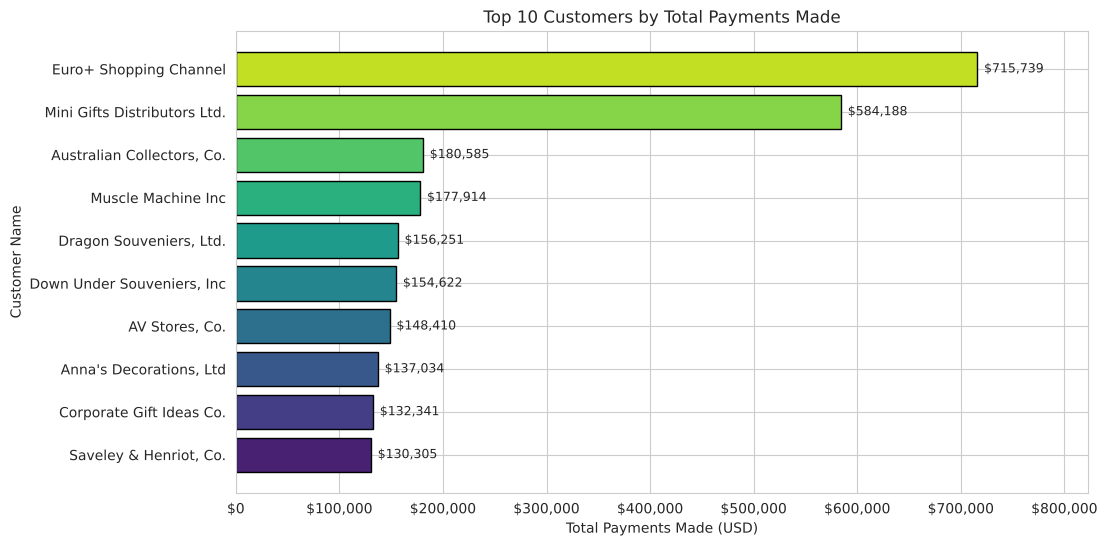

In [7]:
# Produce a visual to represent the top ten customers in terms of total payments
fig, ax = plt.subplots(figsize=(11, 6))

# Horizontal bars read easily with long customer names; largest at the top
plot_df = top_10_customers.sort_values('total_payments')
colors = sns.color_palette('viridis', len(plot_df))
bars = ax.barh(plot_df['customerName'], plot_df['total_payments'], color=colors, edgecolor='black')

for bar, value in zip(bars, plot_df['total_payments']):
    ax.annotate(f'${value:,.0f}', (value, bar.get_y() + bar.get_height() / 2),
                xytext=(5, 0), textcoords='offset points', va='center', fontsize=9)

ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.set_xlim(0, plot_df['total_payments'].max() * 1.15)
ax.set_xlabel('Total Payments Made (USD)')
ax.set_ylabel('Customer Name')
ax.set_title('Top 10 Customers by Total Payments Made')
plt.show()

### Step 6: Top Customer + Product Quantities
The product team is running an analysis on popular and common products sold to each customer in order to try and determine what new products they should be looking at to include in their catalog. This data will also be used by individual sales reps to recommend similar products to each customer next time they place an order. 

They have asked you to query information, for each customer, about any product they have purchased 10 or more units of. In addition they would like the full set of data to be sorted in ascending order by the total amount purchased.

Execute a SQl query that returns the information required to address this ask.

Hint: For this one, you'll need to make use of HAVING, GROUP BY, and ORDER BY — make sure you get the order of them correct!

In [8]:
# For each customer, every product they bought 10 or more units of,
# sorted in ascending order by the total quantity purchased
customer_product_quantities = pd.read_sql("""
SELECT c.customerNumber,
       c.customerName,
       pr.productCode,
       pr.productName,
       SUM(CAST(od.quantityOrdered AS INTEGER)) AS total_quantity_purchased
FROM customers AS c
JOIN orders AS o
    ON c.customerNumber = o.customerNumber
JOIN orderdetails AS od
    ON o.orderNumber = od.orderNumber
JOIN products AS pr
    ON od.productCode = pr.productCode
GROUP BY c.customerNumber, c.customerName, pr.productCode, pr.productName
HAVING SUM(CAST(od.quantityOrdered AS INTEGER)) >= 10
ORDER BY total_quantity_purchased ASC;
""", conn)

customer_product_quantities

,customerNumber,customerName,productCode,productName,total_quantity_purchased
0,314,Petit Auto,S18_2949,1913 Ford Model T Speedster,10
1,412,"Extreme Desk Decorations, Ltd",S24_4620,1961 Chevrolet Impala,10
2,119,La Rochelle Gifts,S32_2509,1954 Greyhound Scenicruiser,11
3,328,Tekni Collectables Inc.,S700_1691,American Airlines: B767-300,11
4,450,The Sharp Gifts Warehouse,S24_3191,1969 Chevrolet Camaro Z28,13
...,...,...,...,...,...
2526,141,Euro+ Shopping Channel,S24_3432,2002 Chevy Corvette,174
2527,141,Euro+ Shopping Channel,S12_4473,1957 Chevy Pickup,183
2528,141,Euro+ Shopping Channel,S24_1444,1970 Dodge Coronet,197
2529,141,Euro+ Shopping Channel,S24_2840,1958 Chevy Corvette Limited Edition,245


### Step 7: Product Analysis - Visual Required

The product team is looking into the demand across its different product lines. They are conducting a comprehensive review of its product portfolio and inventory management strategies. You have been asked to query data pertaining to each different product line, that contains the total quantity ordered and the total number of products for each respective product line. By examining the number of products and total quantity ordered for each product line, the company aims to:
1. Optimize product mix:
    - Identify which product lines have the most diverse offerings (high number of products)
    - Determine which lines are most popular (high total quantity ordered)
    - Compare if lines with more products necessarily lead to more orders
2. Improve inventory management:
    - Adjust stock levels based on the popularity of each product line
    - Identify potential overstocking in lines with low order quantities
    - Ensure adequate variety in high-performing product lines
3. Adjust marketing strategy:
    - Focus promotional efforts on product lines with high potential (many products but lower order quantities)
    - Capitalize on the popularity of high-performing lines in marketing campaigns
4. Advise Product development:
    - Invest in expanding product ranges for lines with high order quantities
    - Consider phasing out or revamping product lines with low numbers of products and low order quantities

Hint: Think about how you can and might have to utilize SQL DISTINCT statement

Execute a SQl query that returns the information required to address this ask.

In [9]:
# Number of products and total quantity ordered for each product line
# COUNT(DISTINCT ...) stops a product being counted once per order line
product_line_summary = pd.read_sql("""
SELECT p.productLine,
       COUNT(DISTINCT p.productCode) AS num_products,
       COALESCE(SUM(CAST(od.quantityOrdered AS INTEGER)), 0) AS total_quantity_ordered
FROM products AS p
LEFT JOIN orderdetails AS od
    ON p.productCode = od.productCode
GROUP BY p.productLine
ORDER BY total_quantity_ordered DESC;
""", conn)

product_line_summary

,productLine,num_products,total_quantity_ordered
0,Classic Cars,38,35582
1,Vintage Cars,24,22933
2,Motorcycles,13,12778
3,Planes,12,11872
4,Trucks and Buses,11,11001
5,Ships,9,8532
6,Trains,3,2818


Once you have the information returned in a dataframe, select an appropriate visualization to represent the relationship between total quantity ordered and the number of products in order to perform a preliminary investigation into the question of if more products lead to more orders. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

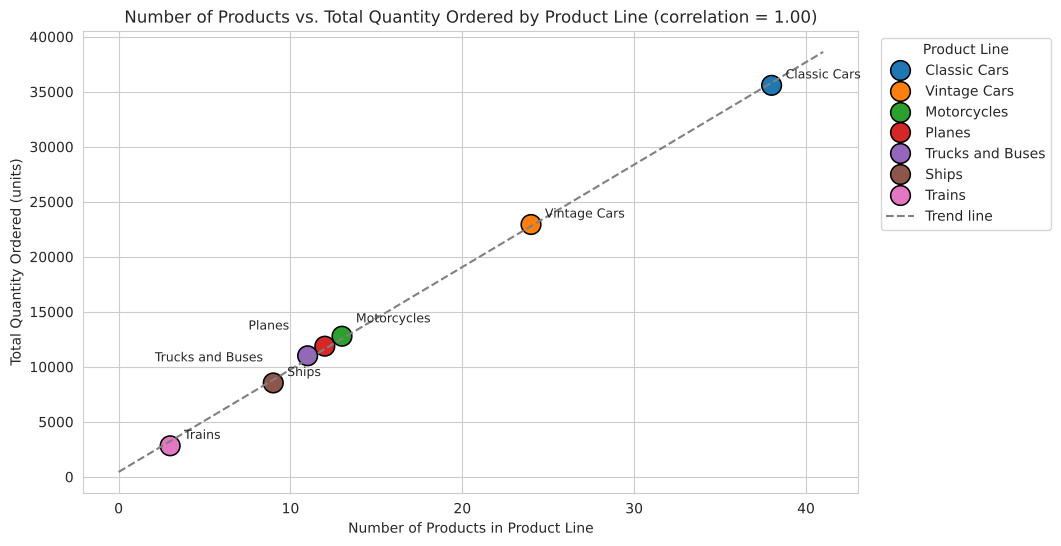

In [10]:
# Produce a visual to represent the the relation between number of products and the total amount ordered
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(data=product_line_summary, x='num_products', y='total_quantity_ordered',
                hue='productLine', s=200, palette='tab10', edgecolor='black', ax=ax)

# Trend line to show the overall direction of the relationship
slope, intercept = np.polyfit(product_line_summary['num_products'], product_line_summary['total_quantity_ordered'], 1)
x_line = np.linspace(0, product_line_summary['num_products'].max() + 3, 100)
ax.plot(x_line, slope * x_line + intercept, color='gray', linestyle='--', label='Trend line')

# Label each point with its product line
# (custom offsets keep the labels of the closely grouped lines from overlapping)
label_offsets = {'Motorcycles': (10, 10), 'Planes': (-55, 12), 'Trucks and Buses': (-110, -4)}
for _, row in product_line_summary.iterrows():
    ax.annotate(row['productLine'], (row['num_products'], row['total_quantity_ordered']),
                xytext=label_offsets.get(row['productLine'], (10, 5)),
                textcoords='offset points', fontsize=9)

corr = product_line_summary['num_products'].corr(product_line_summary['total_quantity_ordered'])
ax.set_xlabel('Number of Products in Product Line')
ax.set_ylabel('Total Quantity Ordered (units)')
ax.set_title(f'Number of Products vs. Total Quantity Ordered by Product Line (correlation = {corr:.2f})')
ax.legend(title='Product Line', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

## Reflection Question:

Please explain your choice in the type of visual you used in order to highlight and represent the data from the above query. In a non-technical manner explain why that chart type makes sense for the information being conveyed. What does this visual convey in the context of the question it was asked for?

## Type your answer in markdown here!

I used a **scatter plot**, because the question asks about the **relationship between two numbers**: how many products a line offers and how many units customers ordered. A scatter plot places each product line as a single dot, with the number of products across the bottom and the total quantity ordered up the side. If more products led to more orders, the dots would rise from left to right. A bar chart could show each number separately, but it would not show how the two move together.

To make it easier to read, I labelled every dot with its product line, gave each line its own color, and added a dashed trend line showing the overall direction.

**What it shows:** the dots rise steadily from left to right and sit close to the trend line, a very strong positive relationship (correlation close to 1). Product lines with more products, such as **Classic Cars** (38 products) and **Vintage Cars** (24 products), have by far the highest quantities ordered, while **Trains**, with only 3 products, has the lowest. This suggests that offering more variety within a line goes along with more orders. Because the dots sit close to the line, total orders appear to be driven mainly by how many products a line offers, rather than some lines selling unusually well per product. One caution: this shows the two move together, not that adding products *causes* more orders.

### Step 8: Remote Offices
Upper management is considering a shift to hybrid and remote work for certain locations and roles. They have tasked you with providing them data about employees who work in any office that has fewer than 5 total employees so they can better understand how to support those employees remotely when offices are shut down. 

Be sure to include information about the employees job and supervisor so management can adjust everyone to remote work properly.

Hint: Utilize a subquery to find the relevant offices

Execute a SQl query that returns the information required to address this ask.

In [11]:
# Employees in offices with fewer than 5 total employees,
# including their job title and their supervisor's details
remote_office_employees = pd.read_sql("""
SELECT e.employeeNumber,
       e.firstName,
       e.lastName,
       e.jobTitle,
       e.email,
       e.officeCode,
       o.city AS officeCity,
       o.country AS officeCountry,
       e.reportsTo AS supervisorEmployeeNumber,
       s.firstName || ' ' || s.lastName AS supervisorName,
       s.jobTitle AS supervisorJobTitle
FROM employees AS e
JOIN offices AS o
    ON e.officeCode = o.officeCode
LEFT JOIN employees AS s
    ON e.reportsTo = s.employeeNumber
WHERE e.officeCode IN (
    SELECT officeCode
    FROM employees
    GROUP BY officeCode
    HAVING COUNT(employeeNumber) < 5
)
ORDER BY e.officeCode, e.lastName;
""", conn)

remote_office_employees

,employeeNumber,firstName,lastName,jobTitle,email,officeCode,officeCity,officeCountry,supervisorEmployeeNumber,supervisorName,supervisorJobTitle
0,1188,Julie,Firrelli,Sales Rep,jfirrelli@classicmodelcars.com,2,Boston,USA,1143,Anthony Bow,Sales Manager (NA)
1,1216,Steve,Patterson,Sales Rep,spatterson@classicmodelcars.com,2,Boston,USA,1143,Anthony Bow,Sales Manager (NA)
2,1286,Foon Yue,Tseng,Sales Rep,ftseng@classicmodelcars.com,3,NYC,USA,1143,Anthony Bow,Sales Manager (NA)
3,1323,George,Vanauf,Sales Rep,gvanauf@classicmodelcars.com,3,NYC,USA,1143,Anthony Bow,Sales Manager (NA)
4,1625,Yoshimi,Kato,Sales Rep,ykato@classicmodelcars.com,5,Tokyo,Japan,1621,Mami Nishi,Sales Rep
5,1621,Mami,Nishi,Sales Rep,mnishi@classicmodelcars.com,5,Tokyo,Japan,1056,Mary Patterson,VP Sales
6,1611,Andy,Fixter,Sales Rep,afixter@classicmodelcars.com,6,Sydney,Australia,1088,William Patterson,Sales Manager (APAC)
7,1619,Tom,King,Sales Rep,tking@classicmodelcars.com,6,Sydney,Australia,1088,William Patterson,Sales Manager (APAC)
8,1612,Peter,Marsh,Sales Rep,pmarsh@classicmodelcars.com,6,Sydney,Australia,1088,William Patterson,Sales Manager (APAC)
9,1088,William,Patterson,Sales Manager (APAC),wpatterson@classicmodelcars.com,6,Sydney,Australia,1056,Mary Patterson,VP Sales


## Reflection Question:

Describe how you decided on the subquery that you used in the query above? This answer can be technically in nature, describing your thought process in how the main query is utilizing the subquery to return the correct data.

## Type your answer in markdown here!

I split the problem into two questions: **which offices qualify**, and **who works in them**.

1. **Which offices qualify (the subquery):** an office's size is not stored anywhere, so it has to be calculated. The subquery groups the `employees` table by `officeCode`, counts the employees in each group, and uses `HAVING COUNT(employeeNumber) < 5` to keep only the small offices. `HAVING` is needed instead of `WHERE` because the filter is on an aggregate (a count), which only exists after grouping. The subquery returns a simple list of office codes (2, 3, 5, 6 and 7). Office 1 (6 employees) and office 4 (5 employees) are left out.
2. **Who works in them (the main query):** the outer query uses `WHERE e.officeCode IN (subquery)`, so an employee is kept only if their office code appears in that list. The main query then joins `offices` to add the office city and country, and **self-joins** `employees` (as `s`) on `e.reportsTo = s.employeeNumber` to add each employee's supervisor name and job title, as management asked. I used a `LEFT JOIN` for the supervisor so that an employee without a supervisor would still appear.

Using a subquery instead of typing the office codes by hand means the query stays correct if employees join or leave: the list of small offices is recalculated every time the query runs.

### Step 9: Close the Connection

Now that you are finished executing your queries and retrieving the required information you always want to make sure to close the connection to your database.

In [12]:
# Close the connection to the database
conn.close()

### End of Guided Section
In this initial portion of the assessment, you produced several data queries and visualizations for a model company, mainly focused around its customer and product data. You wrote and engineered specific SQL queries to address pertinent questions and asks from the company. Along the way, you utilized many of the major concepts and keywords associated with SQL SELECT queries: FROM, WHERE, GROUP BY, HAVING, ORDER BY, JOIN, SUM, COUNT, and AVG.

## Part 2: Exploratory Analysis with SQL
In this open-ended exploratory section, you will analyze real-world data from the movie industry. As a data analyst, you have the freedom to investigate questions and topics that intrigue you within this dataset. The database schema and Entity-Relationship Diagram (ERD) are provided below for your reference. A general overview and instructions are also provided below.

In [13]:
# Run this cell without changes
import zipfile

zip_file_path = 'im.db.zip'
extract_to_path = './'

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to_path)

# Connection
conn4 = sqlite3.connect('im.db')

# Schema
schema_df = pd.read_sql("""
SElECT * FROM sqlite_master                        
""", conn4)
schema_df

,type,name,tbl_name,rootpage,sql
0,table,movie_basics,movie_basics,2,"CREATE TABLE ""movie_basics"" (\n""movie_id"" TEXT..."
1,table,directors,directors,3,"CREATE TABLE ""directors"" (\n""movie_id"" TEXT,\n..."
2,table,known_for,known_for,4,"CREATE TABLE ""known_for"" (\n""person_id"" TEXT,\..."
3,table,movie_akas,movie_akas,5,"CREATE TABLE ""movie_akas"" (\n""movie_id"" TEXT,\..."
4,table,movie_ratings,movie_ratings,6,"CREATE TABLE ""movie_ratings"" (\n""movie_id"" TEX..."
5,table,persons,persons,7,"CREATE TABLE ""persons"" (\n""person_id"" TEXT,\n ..."
6,table,principals,principals,8,"CREATE TABLE ""principals"" (\n""movie_id"" TEXT,\..."
7,table,writers,writers,9,"CREATE TABLE ""writers"" (\n""movie_id"" TEXT,\n ..."


## The Data

![movie ERD](images/movie_data_erd.jpeg)
### Database Content:

- Source: IMDB
- Time Range: Movies released between 2010 and 2019
- Note: Exclude any movies with a start_year after 2019 as this data is not current or accurate

Available Data Categories:
- Genre
- Runtime
- Personnel (writers, directors, actors)
- Movie ratings

### Objectives:

Initial Exploration:
- Use SQL in combination with Pandas to explore the database
- Identify interesting trends, patterns, or relationships in the data

Business Question Formulation:
- Develop at least one substantial business question for deeper analysis
- Ensure the question is relevant, specific, and can be addressed with the available data

Data Cleaning Assessment:
- Identify potential data cleaning tasks necessary for your deeper analysis
- Note: You are not required to perform the cleaning, only to recognize and list the necessary tasks

Null Value Handling:
- Be aware that the dataset contains null values in certain fields
- Exclude these null values from your exploration
- Do not attempt to input or fill in missing information

### Deliverables:

You need to produce a short slide presentation (3-5 slides) that highlights the three key deliverables below. Utilize a data visualization to support the second deliverable.

1. A summary of your initial data exploration findings
    - Can be bulleted or sentence form
2. At least one well-formulated business question for further analysis
    - Should stem from a relevant trend or pattern your initial exploration identified
3. A list of potential data cleaning tasks identified during your exploration
    - This can and should include things like data normalization/standardization and null handling

Tips for Success:

Begin with broad exploratory queries to understand the data's scope and content. Then focus on honing in on interesting relationships between different data categories. Consider industry trends, audience preferences, or financial aspects when formulating your business question. Pay attention to data quality issues, inconsistencies, or limitations that might affect your analysis. Remember, the goal is to demonstrate your analytical thinking and ability to derive meaningful insights from complex datasets. Good luck with your exploration!

NOTE: You do not need to explore every aspect of this database. Find something that you think is interesting or relevant about the data and focus your exploration there.

## Part 2: Initial Exploration

I start with broad queries to understand the size and contents of the main tables, keeping only movies released in or before 2019 as instructed.

In [14]:
# Size of each table in the database
table_sizes = pd.read_sql("""
SELECT 'movie_basics' AS table_name, COUNT(*) AS num_rows FROM movie_basics
UNION ALL SELECT 'movie_ratings', COUNT(*) FROM movie_ratings
UNION ALL SELECT 'directors', COUNT(*) FROM directors
UNION ALL SELECT 'writers', COUNT(*) FROM writers
UNION ALL SELECT 'principals', COUNT(*) FROM principals
UNION ALL SELECT 'persons', COUNT(*) FROM persons
UNION ALL SELECT 'known_for', COUNT(*) FROM known_for
UNION ALL SELECT 'movie_akas', COUNT(*) FROM movie_akas;
""", conn4)

table_sizes

,table_name,num_rows
0,movie_basics,146144
1,movie_ratings,73856
2,directors,291174
3,writers,255873
4,principals,1028186
5,persons,606648
6,known_for,1638260
7,movie_akas,331703


In [15]:
# Number of movies released per year (start_year after 2019 excluded)
movies_per_year = pd.read_sql("""
SELECT start_year, COUNT(*) AS num_movies
FROM movie_basics
WHERE start_year <= 2019
GROUP BY start_year
ORDER BY start_year;
""", conn4)

movies_per_year

,start_year,num_movies
0,2010,11849
1,2011,12900
2,2012,13787
3,2013,14709
4,2014,15589
5,2015,16243
6,2016,17272
7,2017,17504
8,2018,16849
9,2019,8379


In [16]:
# How many movies have missing genres or runtimes, and how many are dated after 2019
missing_values = pd.read_sql("""
SELECT COUNT(*) AS total_movies,
       SUM(CASE WHEN genres IS NULL THEN 1 ELSE 0 END) AS missing_genres,
       SUM(CASE WHEN runtime_minutes IS NULL THEN 1 ELSE 0 END) AS missing_runtime,
       SUM(CASE WHEN start_year > 2019 THEN 1 ELSE 0 END) AS after_2019
FROM movie_basics;
""", conn4)

missing_values

,total_movies,missing_genres,missing_runtime,after_2019
0,146144,5408,31739,1063


In [17]:
# Join movies with their ratings, excluding nulls and movies after 2019
movies_rated = pd.read_sql("""
SELECT mb.movie_id,
       mb.primary_title,
       mb.start_year,
       mb.runtime_minutes,
       mb.genres,
       mr.averagerating,
       mr.numvotes
FROM movie_basics AS mb
JOIN movie_ratings AS mr
    ON mb.movie_id = mr.movie_id
WHERE mb.start_year <= 2019
  AND mb.genres IS NOT NULL
  AND mb.runtime_minutes IS NOT NULL;
""", conn4)

print('Rated movies with complete data:', len(movies_rated))
movies_rated[['runtime_minutes', 'averagerating', 'numvotes']].describe().round(1)

Rated movies with complete data: 65720


,runtime_minutes,averagerating,numvotes
count,65720.0,65720.0,65720.0
mean,94.7,6.3,3954.7
std,209.4,1.5,32088.2
min,3.0,1.0,5.0
25%,81.0,5.5,16.0
50%,91.0,6.5,62.0
75%,104.0,7.3,352.0
max,51420.0,10.0,1841066.0


In [18]:
# How reliable are the ratings? Share of movies with very few votes
print(f"Movies with fewer than 100 votes: {(movies_rated['numvotes'] < 100).mean():.1%}")
print(f"Movies with at least 1,000 votes: {(movies_rated['numvotes'] >= 1000).sum():,}")
print(f"Longest runtime in the data: {movies_rated['runtime_minutes'].max():,.0f} minutes")
print(f"Movies listed as longer than 300 minutes: {(movies_rated['runtime_minutes'] > 300).sum()}")

# Genres are stored as a comma-separated list of up to 3 genres
print("\nNumber of genres listed per movie:")
print(movies_rated['genres'].str.split(',').str.len().value_counts().sort_index())

Movies with fewer than 100 votes: 57.4%
Movies with at least 1,000 votes: 9,607
Longest runtime in the data: 51,420 minutes
Movies listed as longer than 300 minutes: 43

Number of genres listed per movie:
genres
1    30843
2    17037
3    17840
Name: count, dtype: int64


## Business Question

**Which movie genres achieve the highest audience ratings, and do those same genres also attract the largest audiences (number of votes)?**

This matters for a studio deciding which genre to invest in next: a genre that critics and audiences rate highly is not necessarily one that reaches a big audience. To keep the comparison fair, I only include movies with **at least 1,000 votes**, so the averages are not distorted by films rated by a handful of people, and only genres with **at least 50 such movies**.

In [19]:
# Split the comma-separated genres so each movie counts towards every genre it belongs to
popular_movies = movies_rated[movies_rated['numvotes'] >= 1000].copy()
popular_movies['genre'] = popular_movies['genres'].str.split(',')
genre_movies = popular_movies.explode('genre')

genre_summary = (genre_movies.groupby('genre')
                 .agg(num_movies=('movie_id', 'nunique'),
                      avg_rating=('averagerating', 'mean'),
                      median_votes=('numvotes', 'median'))
                 .query('num_movies >= 50')
                 .sort_values('avg_rating', ascending=False)
                 .round(2))

genre_summary

,num_movies,avg_rating,median_votes
genre,,,
Documentary,741,7.27,2259.0
Biography,701,6.96,4559.0
Sport,196,6.93,2753.5
History,387,6.89,3590.0
Music,283,6.75,3637.0
War,163,6.72,3907.0
Animation,376,6.68,5289.5
Musical,70,6.54,2372.5
Drama,5045,6.49,3789.0


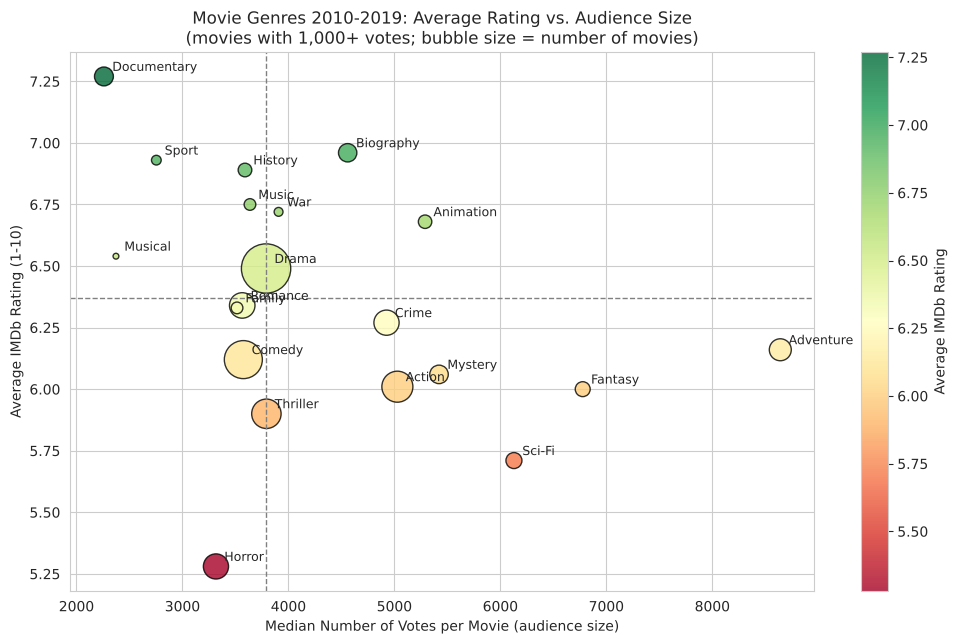

In [20]:
# Visual: average rating vs. typical audience size for each genre
fig, ax = plt.subplots(figsize=(12, 7))

scatter = ax.scatter(genre_summary['median_votes'], genre_summary['avg_rating'],
                     s=genre_summary['num_movies'] / 4, c=genre_summary['avg_rating'],
                     cmap='RdYlGn', edgecolor='black', alpha=0.8)

for genre, row in genre_summary.iterrows():
    ax.annotate(genre, (row['median_votes'], row['avg_rating']),
                xytext=(6, 4), textcoords='offset points', fontsize=9)

# Reference lines at the overall averages split the chart into four groups
ax.axhline(genre_summary['avg_rating'].mean(), color='gray', linestyle='--', linewidth=1)
ax.axvline(genre_summary['median_votes'].median(), color='gray', linestyle='--', linewidth=1)

fig.colorbar(scatter, ax=ax, label='Average IMDb Rating')
ax.set_xlabel('Median Number of Votes per Movie (audience size)')
ax.set_ylabel('Average IMDb Rating (1-10)')
ax.set_title('Movie Genres 2010-2019: Average Rating vs. Audience Size\n(movies with 1,000+ votes; bubble size = number of movies)')
plt.show()

In [21]:
# Supporting check: does runtime relate to rating for popular movies?
runtime_corr = popular_movies['runtime_minutes'].corr(popular_movies['averagerating'])
print(f"Correlation between runtime and rating (movies with 1,000+ votes): {runtime_corr:.2f}")

Correlation between runtime and rating (movies with 1,000+ votes): 0.31


## Summary of Initial Exploration Findings

- The database covers about **146,000 movies**, with releases growing every year from **11,849 in 2010 to 17,504 in 2017**. The count for 2019 is lower and later years contain very few, unreliable records, which is why movies after 2019 are excluded.
- Only about **65,700 movies** have a rating, a genre and a runtime. The others are missing at least one of these.
- Ratings are very uneven in reliability: **more than half of rated movies (57%) have fewer than 100 votes**, so only movies with at least 1,000 votes (about 9,600) were used for the genre comparison.
- **Documentary (7.27), Biography (6.96), Sport (6.93) and History (6.89)** have the highest average ratings, while **Horror (5.28), Sci-Fi (5.71) and Thriller (5.90)** have the lowest.
- The highest-rated genres are **not** the ones with the biggest audiences: **Adventure, Fantasy, Sci-Fi and Mystery** have the highest median vote counts (5,400 to 8,600 votes per movie), but below-average ratings.
- **Drama** is by far the most common genre (over 5,000 popular movies), followed by **Comedy** and **Action**.
- Longer movies tend to be rated slightly higher (correlation of about **0.31**), a weak-to-moderate relationship.

**Answer to the business question:** the genres audiences rate most highly (documentary, biography, history) attract smaller audiences, while the genres that draw the largest audiences (adventure, sci-fi, fantasy) are rated below average. **Animation** and **Biography** stand out as the best balance of above-average ratings and above-average audience size, making them strong candidates for further investigation.

## Potential Data Cleaning Tasks

1. **Exclude movies after 2019:** `movie_basics` contains about 1,060 movies with a `start_year` after 2019, including impossible years such as 2115.
2. **Handle null values:** about 5,400 movies have no `genres` and about 31,700 have no `runtime_minutes`. Following the instructions these were excluded rather than filled in. In `persons`, most `birth_year` and `death_year` values are also missing.
3. **Split and normalize multi-value genres:** `genres` stores up to three genres in one comma-separated string (for example "Action,Crime,Drama"). It needs to be split into one row per genre, or into a separate genre table, before analysis.
4. **Fix extreme runtime outliers:** some runtimes are clearly wrong, for example 51,420 minutes (over 35 days), and 43 movies are listed as longer than 300 minutes. These should be checked and removed or capped.
5. **Filter unreliable ratings:** many ratings are based on very few votes (more than half have fewer than 100), so a minimum vote threshold should be applied.
6. **Remove duplicate rows:** the `directors` table contains about 127,600 duplicate movie/director pairs, which would double-count directors in joins. There are also about 2,000 repeated title and year combinations in `movie_basics` that need checking.
7. **Standardize data types and text:** `primary_profession` in `persons` and `characters` in `principals` are stored as lists inside text strings and would need parsing. Text fields such as titles and names should have consistent whitespace and capitalization.

In [22]:
# Close the connection to the movie database
conn4.close()